![Banner](../../../Images/Banner/09_distributed_spatial_datas.png)

# Map Algebra, Focal Operations and Terrain on Chunked and GPU Rasters

Raster analysis is built from three kinds of operation: **local** (each output pixel from the same
pixel of one or more inputs), **focal** (from a moving window around it) and **zonal** (from all
pixels of a region, notebook 05). This notebook runs the first two at scale with
`geolattice.distributed.raster`: map algebra on the 15 Great Plains covariates, moving-window
statistics and convolutions, and the standard terrain derivatives of the 262 million pixel DEM, on
all CPU cores and on the GPU. It checks that chunked results equal whole-array results at chunk
edges, measures which operations gain most from a GPU, and ends by processing every pixel of the
152 billion pixel 10 m Cropland Data Layer without ever holding more than a few chunks in memory.

## Overview

### Local, focal and zonal

| Kind | Output pixel depends on | Examples | Parallel pattern |
|---|---|---|---|
| Local | the same pixel of each input | arithmetic, NDVI, reclassification, masks | any chunking; no communication |
| Focal | a window of `k x k` pixels around it | moving mean or median, convolution, slope, curvature | chunks plus a halo of `k // 2` pixels |
| Zonal | every pixel of its zone | mean NDVI by county | partial sums per chunk, combined at the end |
| Global | possibly every pixel | flow accumulation, cost distance, viewshed | hard to chunk (notebook 08) |

### Edges

A moving window at the edge of the raster reaches outside it. GeoLattice repeats the nearest edge
value there (`mode="nearest"`), the same rule SciPy uses, so a chunked result and a whole-array
result agree everywhere, including the raster border. NaN propagates: any window containing a
NaN gives NaN for means and convolutions, so fill gaps first if that matters.

### Arithmetic intensity

What a GPU or more cores can gain depends on how much arithmetic an operation does per byte it
reads. Slope does a few operations per pixel and is limited by memory bandwidth; a 9 x 9 median
sorts 81 values per pixel and is limited by arithmetic. Reading a compressed file is limited by
decompression on the CPU. The timings below show all three regimes.

### Terrain derivatives

GeoLattice computes them from the 3 x 3 neighbourhood with Horn's (1981) finite differences:

| Function | Quantity | Units |
|---|---|---|
| `slope` | steepest gradient | degrees, radians or percent |
| `aspect` | direction of steepest descent, clockwise from north | degrees |
| `hillshade` | illumination from a light source (azimuth 315, altitude 45 by default) | 0 to 255 |
| `curvature` | Laplacian (total) curvature: negative on ridges, positive in hollows | 1/m |
| `tpi` | elevation minus the mean of a `window` x `window` neighbourhood | m |
| `tri` | terrain ruggedness index (Riley et al. 1999) | m |
| `roughness` | largest minus smallest elevation in the 3 x 3 window | m |

## Raster Processing with GeoLattice

| Function | Kind | Notes |
|---|---|---|
| `pdist.raster.calc(expr, **layers)` | local | an expression string or a function of named layers |
| `where(cond, a, b)`, `normalize`, `normalized_difference` | local | `a`, `b` may be scalars |
| `reclassify(bins=, values=)` or `reclassify(mapping=)` | local | classes from intervals or exact values; output float32 |
| `map_tiles(obj, func, overlap=)` | local or focal | any `func(block, xp)` written with `xp` runs on NumPy and CuPy |
| `focal(obj, stat, size=)` | focal | mean, sum, min, max, median, std |
| `convolve(obj, kernel)` | focal | any odd-sized kernel |
| `slope`, `aspect`, `hillshade`, `curvature`, `tpi`, `tri`, `roughness` | focal | resolution from the coordinates |

Every function takes `compute=` and `chunks=`, keeps the input's type, laziness and memory space,
and adds the halo its window needs.

### Learning objectives

1. Classify raster operations as local, focal, zonal or global and choose the parallel pattern.
2. Write map algebra over several large rasters with `calc`, `where` and `reclassify`.
3. Run focal statistics and convolutions and confirm that chunked results equal whole-array
   results at chunk edges.
4. Compute terrain derivatives of a 262 million pixel DEM and compare them with published layers.
5. Measure CPU and GPU times and explain them with arithmetic intensity.
6. Process the 152 billion pixel CDL out of core with a lookup-table reclassification, and
   aggregate it to a coarser grid.

### Data

| Dataset | Content |
|---|---|
| Great Plains covariates | 90 m, 17,196 x 15,245 pixels, EPSG:5070: elevation, slope, slope length, K factor and others |
| 2025 CONUS CDL | 10 m, 316,295 x 480,509 pixels (152 billion), uint8 crop codes, 15 GB, EPSG:5070 |

### Contents

- Setup
- Map algebra on the covariates
- Focal statistics and convolution
- Terrain derivatives of the Great Plains
- CPU and GPU, operation by operation
- Every pixel of the 10 m CDL, out of core
- From 10 m crop codes to a 300 m crop fraction
- Summary and exercises

## Setup

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings
import os  # environment and CPU count
import time  # wall-clock timing
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import geopandas as gpd  # vector data
import xarray as xr  # labelled rasters

import geolattice  # GeoLattice
import geolattice.distributed as pdist  # distributed and GPU spatial computing
import dist_data as dd  # chapter helper: paths, cached downloads, timers

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
pd.set_option("display.width", 140)  # wider printed tables
OUT = Path("outputs")  # results and scratch files written by this chapter
OUT.mkdir(exist_ok=True)  # create it if needed
caps = pdist.capabilities()  # engines and GPUs on this machine
print("GeoLattice", geolattice.__version__, "|", os.cpu_count(), "CPU cores |", caps["gpus"], "GPU(s)",  # versions
      f"({caps.get('gpu_memory_total', 0) / 1e9:.0f} GB)" if caps["gpus"] else "")  # GPU memory

import dask  # Dask configuration
import dask.array as da  # chunked arrays
import scipy.ndimage as ndi  # whole-array filters for checks


def sync():  # wait for queued GPU work so timings are real
    if caps["gpus"]:  # only with a GPU
        import cupy as cp  # GPU arrays
        cp.cuda.Device().synchronize()  # block until done


def best_of(fn, n=2):  # best wall time of n runs after a warm-up run
    fn(); sync()  # warm-up
    times = []  # timings
    for _ in range(n):  # timed runs
        t = time.perf_counter(); fn(); sync(); times.append(time.perf_counter() - t)  # one run
    return min(times)  # best

GeoLattice 0.3.49 | 24 CPU cores | 1 GPU(s) (17 GB)


## Map algebra on the covariates

`pdist.raster.calc` evaluates an expression over named layers. As an example, a relative erosion
potential combines soil erodibility (K factor), slope length and the sine of the slope, the three
terrain and soil terms of the Universal Soil Loss Equation (without rainfall and cover). The
layers stay lazy, so nothing is read until the result is used.

In [2]:
lay = {n: dd.gp_raster(n) for n in ["kfactor", "slopeleng", "slope"]}  # three lazy covariates
erosion = pdist.raster.calc("kfactor * sqrt(slopeleng) * sin(slope * pi / 180)", **lay)  # expression over layers
print("lazy:", pdist.is_lazy(erosion), "| chunks:", erosion.data.npartitions, "| dtype:", erosion.dtype)  # still a recipe
q = np.nanpercentile(erosion[::10, ::10].values, [50, 75, 90, 97.5])  # class breaks from every 100th pixel
print("class breaks (median, 75th, 90th, 97.5th percentile):", np.round(q, 4))  # breaks
classes = pdist.raster.reclassify(erosion, bins=list(q), values=[1, 2, 3, 4, 5])  # five classes
steep = pdist.raster.where(lay["slope"] > 15, classes, 0)  # keep classes only on slopes above 15 degrees
with dd.timer("erosion potential, five classes and the steep-land mask for 262 million pixels"):  # run the chain
    cls_small, steep_share = dask.compute(classes[::10, ::10], (steep > 0).mean())  # a preview and one statistic
print(f"share of the Great Plains rectangle that is steep (above 15 degrees): {float(steep_share):.2%}")  # result

lazy: True | chunks: 72 | dtype: float32


class breaks (median, 75th, 90th, 97.5th percentile): [0.0013 0.0242 0.118  0.4143]


erosion potential, five classes and the steep-land mask for 262 million pixels: 2.78 s
share of the Great Plains rectangle that is steep (above 15 degrees): 4.39%


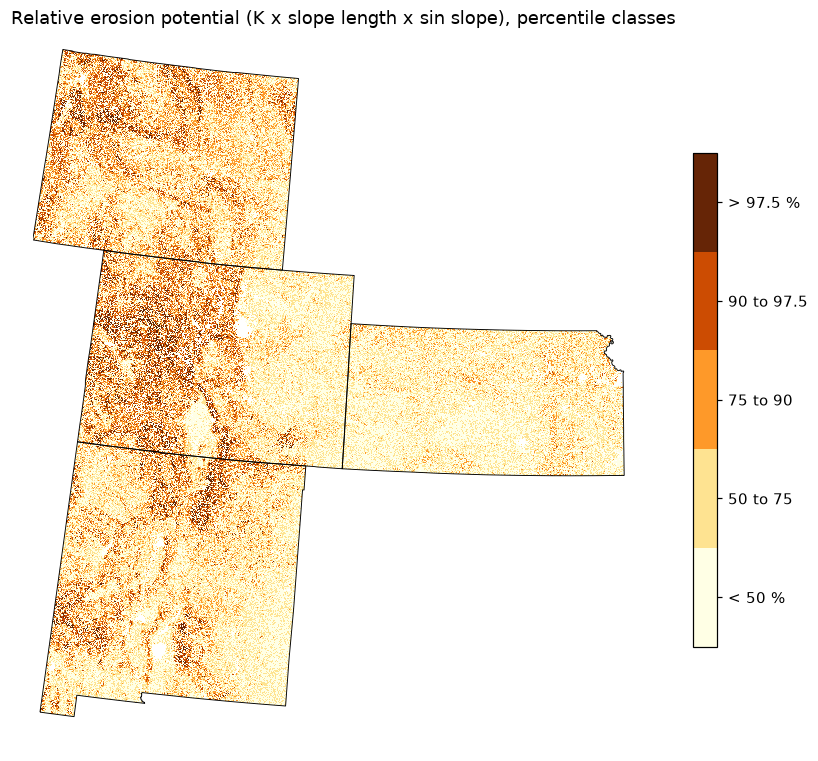

In [3]:
fig, ax = plt.subplots(figsize=(7.5, 7))  # one map
cm = plt.get_cmap("YlOrBr", 5)  # five colours
im = ax.imshow(cls_small, cmap=cm, vmin=0.5, vmax=5.5, extent=dd.extent(cls_small), interpolation="nearest")  # classes
cb = plt.colorbar(im, ax=ax, shrink=0.7, ticks=[1, 2, 3, 4, 5]); cb.ax.set_yticklabels(["< 50 %", "50 to 75", "75 to 90", "90 to 97.5", "> 97.5 %"])  # legend
dd.gp_states().boundary.plot(ax=ax, color="k", lw=0.6)  # states
ax.set_title("Relative erosion potential (K x slope length x sin slope), percentile classes"); ax.set_axis_off()  # title
plt.tight_layout(); plt.show()  # draw

The highest classes follow the Rocky Mountain front and the dissected terrain of Wyoming and New
Mexico, where steep slopes meet long slope lengths; most of Kansas falls in the lowest classes.
The whole chain (three reads, an expression, a reclassification, a mask and two reductions) ran
as one task graph in a few seconds.

## Focal statistics and convolution

`pdist.raster.focal` computes moving-window statistics with the halo each window size needs. The
check below compares the chunked 9 x 9 median, standard deviation and a custom 5 x 5 convolution
with SciPy on the whole window at once, including the pixels along chunk seams.

In [4]:
w = dd.gp_raster("elev")[7000:11096, 3000:7096].compute()  # 4096 x 4096 window in the Colorado mountains
w = w.fillna(float(w.mean()))  # fill the few no-data holes
laplace = np.array([[0, 0, 1, 0, 0], [0, 1, 2, 1, 0], [1, 2, -16, 2, 1], [0, 1, 2, 1, 0], [0, 0, 1, 0, 0]], float)  # 5 x 5 edge kernel
checks = {  # GeoLattice (1024 pixel chunks) and SciPy on the whole window
    "median 9 x 9": (pdist.raster.focal(w, "median", size=9, chunks=(1024, 1024)), ndi.median_filter(w.values, 9, mode="nearest")),
    "std 9 x 9": (pdist.raster.focal(w, "std", size=9, chunks=(1024, 1024)),  # reference in float64 (see below)
                  np.sqrt(np.maximum(ndi.uniform_filter(w.values.astype(float) ** 2, 9, mode="nearest") - ndi.uniform_filter(w.values.astype(float), 9, mode="nearest") ** 2, 0))),
    "convolve 5 x 5": (pdist.raster.convolve(w, laplace, chunks=(1024, 1024)), ndi.convolve(w.values, laplace, mode="nearest")),
}
for name, (mine, ref) in checks.items():  # compare each pair
    print(f"{name:15s} largest difference {np.abs(np.asarray(mine) - ref).max():.2e}")  # agreement

median 9 x 9    largest difference 0.00e+00
std 9 x 9       largest difference 3.66e-04
convolve 5 x 5  largest difference 5.86e-03


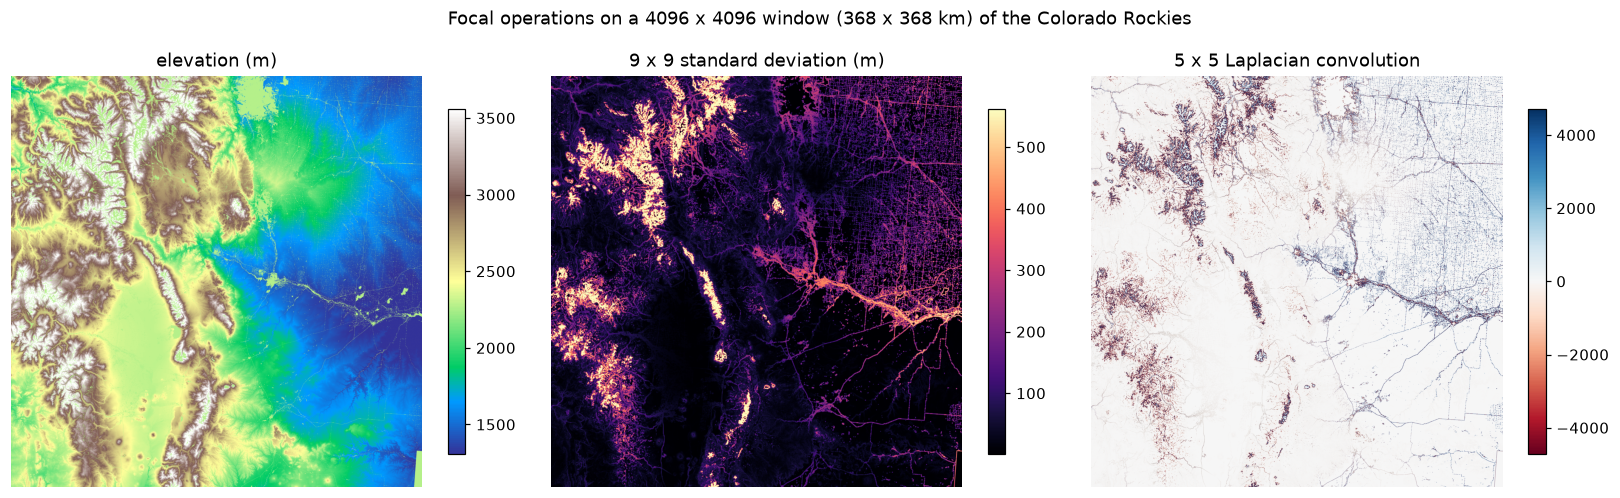

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.8))  # three panels
for a, (name, arr, cmap) in zip(ax, [("elevation (m)", w.values, "terrain"), ("9 x 9 standard deviation (m)", checks["std 9 x 9"][0], "magma"),  # panels
                                      ("5 x 5 Laplacian convolution", checks["convolve 5 x 5"][0], "RdBu")]):  # third
    v = np.nanpercentile(arr, [2, 98])  # robust colour range
    im = a.imshow(arr, cmap=cmap, vmin=-max(abs(v)) if cmap == "RdBu" else v[0], vmax=max(abs(v)) if cmap == "RdBu" else v[1])  # draw
    a.set_title(name); a.set_axis_off(); plt.colorbar(im, ax=a, shrink=0.75)  # labels
plt.suptitle("Focal operations on a 4096 x 4096 window (368 x 368 km) of the Colorado Rockies"); plt.tight_layout(); plt.show()  # draw

The chunked results equal SciPy's whole-array results to float32 rounding, seams included. The
standard deviation needed care: computed as `E[x^2] - E[x]^2` in float32, elevations of 3,000 m
that vary by a few metres lose most of their significant digits (an earlier version of the
function was off by up to 1.7 m here). GeoLattice therefore subtracts each chunk's mean and works
in float64 inside the chunk, and the reference is computed in float64 too. The 9 x 9 standard deviation is a simple measure of local relief: high along the
mountain fronts and canyon walls, low on the plains. The Laplacian kernel highlights ridges
(negative) and valley bottoms (positive).

## Terrain derivatives of the Great Plains

All seven terrain functions run on the full DEM. Because NaN propagates into every window that
touches it, the scattered no-data holes would spread: a 21 x 21 TPI window almost always contains
one. The holes are therefore filled with their nearest valid neighbour first
(`scipy.ndimage.distance_transform_edt` returns that neighbour's index for every pixel), and masked
again afterwards. Slope is also published with the dataset (`slope.tif`), which allows a check
against an independent implementation.

In [6]:
dem = dd.gp_raster("elev").compute()  # 262 million pixels in memory
holes = dem.isnull()  # no-data pixels: outside the states and scattered holes inside
near = ndi.distance_transform_edt(holes.values, return_distances=False, return_indices=True)  # nearest valid pixel of every pixel
dem_f = dem.copy(data=dem.values[tuple(near)])  # holes filled by their nearest valid neighbour
del near  # free 4 GB of indices
terrain = {}  # results
with dd.timer("slope, aspect, hillshade, curvature, TPI, TRI and roughness on all CPU cores"):  # seven passes
    for name, fn in [("slope", pdist.raster.slope), ("aspect", pdist.raster.aspect), ("hillshade", pdist.raster.hillshade),  # functions
                     ("curvature", pdist.raster.curvature), ("tpi", lambda d, **k: pdist.raster.tpi(d, window=21, **k)),  # TPI over 21 x 21 (1.9 km)
                     ("tri", pdist.raster.tri), ("roughness", pdist.raster.roughness)]:  # the rest
        terrain[name] = fn(dem_f, compute="cpu").where(~holes)  # on the filled DEM, holes masked again
published = dd.gp_raster("slope").compute()  # the slope layer shipped with the data
diff = (terrain["slope"] - published).values  # difference in degrees
ok = np.isfinite(diff)  # pixels where both exist
print(f"slope vs published: mean difference {np.mean(diff[ok]):.3f}, mean absolute {np.mean(np.abs(diff[ok])):.3f} degrees,",  # bias and error
      f"correlation {np.corrcoef(terrain['slope'].values[ok], published.values[ok])[0, 1]:.4f}")  # agreement

slope, aspect, hillshade, curvature, TPI, TRI and roughness on all CPU cores: 16.57 s


slope vs published: mean difference -0.784, mean absolute 0.915 degrees, correlation 0.9877


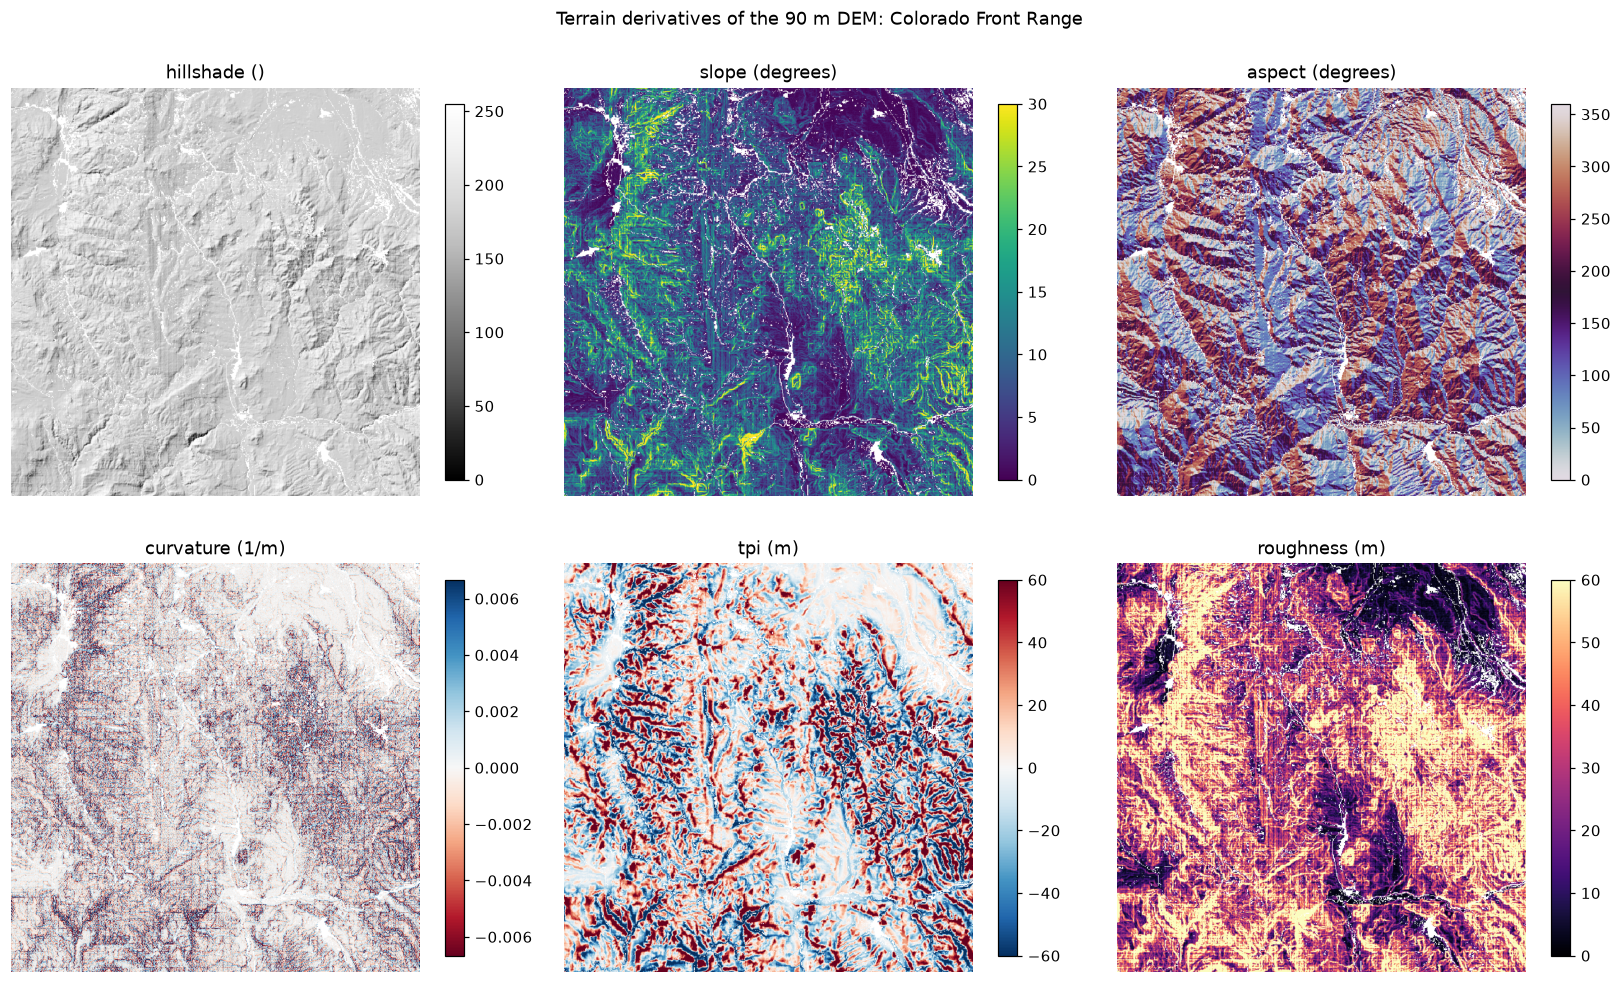

In [7]:
z = (slice(6000, 6800), slice(3700, 4500))  # 72 x 72 km of the Colorado Front Range
fig, ax = plt.subplots(2, 3, figsize=(15, 9.5))  # six panels
panels = [("hillshade", "Greys_r", None), ("slope", "viridis", (0, 30)), ("aspect", "twilight", (0, 360)),  # name, colours, range
          ("curvature", "RdBu", "auto"), ("tpi", "RdBu_r", (-60, 60)), ("roughness", "magma", (0, 60))]  # second row
for a, (name, cmap, rng) in zip(ax.ravel(), panels):  # each panel
    arr = terrain[name].values[z]  # the zoom
    if rng == "auto":  # symmetric range from the data
        v = np.nanpercentile(np.abs(arr), 95); rng = (-v, v)  # 95th percentile of the magnitude
    im = a.imshow(arr, cmap=cmap, vmin=rng[0] if rng else None, vmax=rng[1] if rng else None)  # map
    a.set_title(f"{name} ({terrain[name].attrs.get('units', '')})"); a.set_axis_off(); plt.colorbar(im, ax=a, shrink=0.75)  # labels
plt.suptitle("Terrain derivatives of the 90 m DEM: Colorado Front Range"); plt.tight_layout(); plt.show()  # draw

The computed slope correlates closely with the published layer (0.99), but is on
average about 0.8 degrees lower. The published layer was evidently made with a different method
or from a finer DEM; slope depends on the resolution it is computed at, and steeper values from a
finer grid are the usual result. Curvature, TPI and roughness each pick out ridges, valleys and rough ground in their
own way; notebook 09 uses such layers as predictors. The slope and roughness maps also show a faint
grid of straight lines. They are striping in the source DEM, left over from how it was assembled,
and derivatives amplify such artefacts. Curvature, a second derivative, amplifies them most: at
90 m it is dominated by the striping, while TPI, which averages over 21 x 21 pixels, shows the
ridges and valleys clearly. Check derivative maps for artefacts before using them as predictors,
and smooth the DEM first (`pdist.raster.focal(dem, "mean", size=5)`) when they appear.

## CPU and GPU, operation by operation

Each operation runs on the full in-memory DEM on all CPU cores and on the GPU with the DEM
already in device memory, so the GPU time is compute only.

In [8]:
dem_gpu = pdist.to_gpu(dem) if caps["gpus"] else None  # one copy on the device
ops = {"slope": lambda d, c: pdist.raster.slope(d, compute=c),  # the operations to time
       "hillshade": lambda d, c: pdist.raster.hillshade(d, compute=c),
       "curvature": lambda d, c: pdist.raster.curvature(d, compute=c),
       "TPI 21 x 21": lambda d, c: pdist.raster.tpi(d, window=21, compute=c),
       "roughness": lambda d, c: pdist.raster.roughness(d, compute=c),
       "focal mean 9 x 9": lambda d, c: pdist.raster.focal(d, "mean", size=9, compute=c),
       "focal std 9 x 9": lambda d, c: pdist.raster.focal(d, "std", size=9, compute=c),
       "convolve 5 x 5": lambda d, c: pdist.raster.convolve(d, laplace, compute=c),
       "focal median 9 x 9": lambda d, c: pdist.raster.focal(d, "median", size=9, compute=c)}
rows = []  # timings
for name, op in ops.items():  # each operation
    n = 1 if "median" in name else 2  # the CPU median is slow: one timed run
    cpu = best_of(lambda: op(dem, "cpu"), n=n)  # all CPU cores, NumPy chunks
    gpu = best_of(lambda: op(dem_gpu, "gpu")) if caps["gpus"] else np.nan  # GPU, data resident
    rows.append({"operation": name, "CPU all cores (s)": cpu, "GPU resident (s)": gpu, "GPU speed-up": cpu / gpu})  # row
bench = pd.DataFrame(rows).set_index("operation")  # table
bench.round(3)  # show

,CPU all cores (s),GPU resident (s),GPU speed-up
operation,,,
slope,2.005,0.174,11.544
hillshade,3.438,0.303,11.350
curvature,1.074,0.095,11.358
TPI 21 x 21,0.746,0.074,10.055
roughness,2.244,0.248,9.041
focal mean 9 x 9,0.676,0.057,11.849
focal std 9 x 9,2.249,0.264,8.509
convolve 5 x 5,0.842,0.053,15.983
focal median 9 x 9,22.922,0.523,43.826


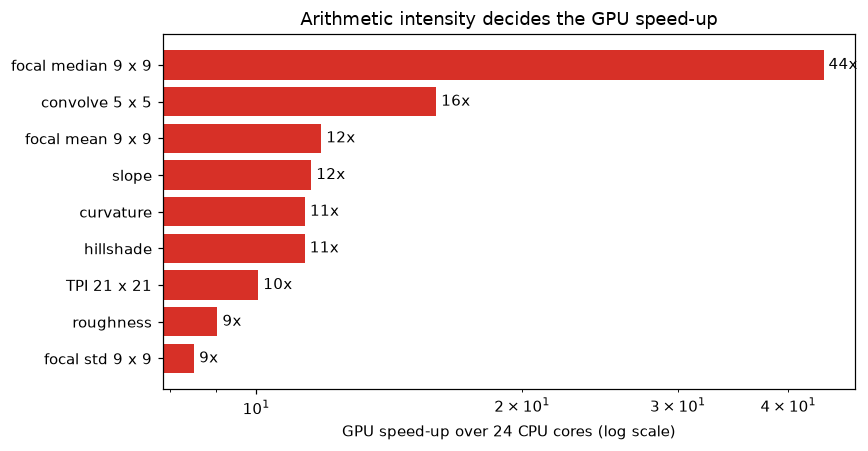

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.2))  # one panel
b = bench.sort_values("GPU speed-up")  # order by speed-up
ax.barh(b.index, b["GPU speed-up"], color="#d73027")  # bars
for i, v in enumerate(b["GPU speed-up"]):  # labels
    ax.text(v, i, f" {v:.0f}x", va="center")  # speed-up
ax.set_xscale("log"); ax.set_xlabel("GPU speed-up over 24 CPU cores (log scale)")  # axis
ax.set_title("Arithmetic intensity decides the GPU speed-up"); plt.tight_layout(); plt.show()  # draw

The memory-bound operations (slope, hillshade, curvature, roughness, the moving mean, the
convolution) gain roughly an order of magnitude: the GPU's memory is that much faster than the
CPU's. The standard deviation gains less, because it now computes in float64, which this laptop
GPU executes at a small fraction of its float32 speed. The 9 x 9 median, which sorts 81 values for every pixel, is
compute-bound and gains the most: the 24 CPU cores needed tens of seconds, the GPU a fraction of
a second. When choosing what to move to a GPU, start with the heavy per-pixel operations.

## Every pixel of the 10 m CDL, out of core

The 2025 CDL has 152 billion pixels, 152 GB as bytes. The task: count every pixel in the United
States by land cover group. The pipeline is lazy from end to end:

1. `dd.cdl()` opens the file with 8192 x 8192 chunks (67 MB of uint8 each, 2,301 chunks).
2. `pdist.raster.map_tiles` reclassifies each chunk with a 256-entry lookup table, which keeps
   the result uint8. (`pdist.raster.reclassify(mapping=...)` would also work but loops over the
   codes and returns float32; for categorical rasters a lookup table is the efficient way.)
3. A per-chunk `bincount` gives 12 numbers per chunk, summed over all chunks.

At no time does more than a few chunks per thread exist in memory; `dd.PeakMemory` samples this
process's memory while the job runs.

In [10]:
import gc  # free memory before measuring
del dem, dem_f, holes, dem_gpu, terrain, published, diff, w, checks  # drop the DEM work of the previous sections
gc.collect()  # return the memory
cdl = dd.cdl()  # lazy, 8192 x 8192 chunks
lut = dd.cdl_lookup()  # CDL code -> group number (0 = no data or outside the US)
groups = pdist.raster.map_tiles(cdl, lambda b, xp: xp.asarray(lut)[b], dtype="uint8", compute="cpu")  # reclassify each chunk
k = len(dd.CDL_GROUPS) + 1  # group numbers 0..11
hist = groups.data.map_blocks(lambda b: np.bincount(b.ravel(), minlength=k)[None, None, :],  # 12 counts per chunk
                              new_axis=2, chunks=(1, 1, k), dtype=np.int64).sum(axis=(0, 1))  # summed over chunks
print(f"{cdl.size / 1e9:.0f} billion pixels in {cdl.data.npartitions:,} chunks; graph of {len(hist.__dask_graph__()):,} tasks")  # size
with dd.PeakMemory() as pm:  # watch memory
    t0 = time.perf_counter()  # start
    counts = hist.compute()  # read, reclassify and count every pixel
    secs = time.perf_counter() - t0  # elapsed
print(f"{secs / 60:.1f} minutes, {cdl.size / secs / 1e6:,.0f} million pixels per second;",  # throughput
      f"process memory {pm.start_gb:.1f} GB before, peak {pm.peak_gb:.1f} GB, an increase of {pm.peak_gb - pm.start_gb:.1f} GB (data: {dd.gb(cdl.nbytes)})")  # memory

152 billion pixels in 2,301 chunks; graph of 18,978 tasks


3.5 minutes, 726 million pixels per second; process memory 11.3 GB before, peak 33.1 GB, an increase of 21.7 GB (data: 151.98 GB)


In [11]:
names = ["No data"] + list(dd.CDL_GROUPS)  # group names in number order
us = pd.DataFrame({"pixels": counts}, index=names)  # counts
us["million ha"] = us.pixels * 100 / 1e4 / 1e6  # 10 x 10 m pixels to million hectares
land = us.drop("No data")  # mapped pixels only
land["share %"] = 100 * land.pixels / land.pixels.sum()  # shares of mapped land
print(f"mapped area {land['million ha'].sum():.0f} million ha (the conterminous US is about 808 million ha)")  # check
land.sort_values("pixels", ascending=False)[["million ha", "share %"]].round(1)  # table

mapped area 808 million ha (the conterminous US is about 808 million ha)


,million ha,share %
Grass and shrubs,337.3,41.8
Forest,189.1,23.4
Water and wetland,90.6,11.2
Developed,52.8,6.5
Corn,40.0,5.0
Soybeans,32.8,4.1
Other crops,28.4,3.5
Wheat,15.2,1.9
Barren and other,11.9,1.5
Fallow,6.4,0.8


The job read the whole 15 GB file once, decompressed it and touched every pixel, while the
process memory grew by a small fraction of the data size: the decompression buffers of 24 parallel
reads and GDAL's block cache, not the data. The mapped total matches the area of the conterminous
United States, and the group areas are plausible: grassland and shrubland dominate, and corn,
soybeans and wheat together cover about a ninth of the land in 2025. The speed is set by
reading and decompressing PackBits blocks on the CPU; there is so little arithmetic per pixel that
a GPU would only add copying.

## From 10 m crop codes to a 300 m crop fraction

A common next step is to aggregate a fine categorical raster to a coarser grid: here the
fraction of each 300 m cell (30 x 30 pixels) that is cropland, for the Great Plains rectangle (21
billion pixels). The chunks are set to multiples of 30 so that `coarsen` never straddles a chunk
edge, and the same pipeline runs once with `compute="cpu"` and once with `compute="gpu"`.

In [12]:
gp = dd.gp_states().total_bounds  # Great Plains extent in EPSG:5070
crop_lut = np.zeros(256, np.float32)  # 1 for crop codes, 0 for other land
for g in dd.CROP_GROUPS:  # crop groups
    crop_lut[dd.CDL_GROUPS[g]] = 1.0  # their codes
crop_lut[0] = np.nan  # no data stays NaN


def crop_fraction(compute):  # 300 m crop fraction of the Great Plains rectangle
    c = dd.cdl(chunks={"y": 7680, "x": 7680}).sel(x=slice(gp[0], gp[2]), y=slice(gp[3], gp[1]))  # lazy window
    c = c.chunk({"y": 7680, "x": 7680})  # chunks that are multiples of 30
    is_crop = pdist.raster.map_tiles(c, lambda b, xp: xp.asarray(crop_lut)[b], dtype="float32", compute=compute)  # 0, 1 or NaN
    return is_crop.coarsen(y=30, x=30, boundary="trim").mean()  # NaN-aware mean of 900 pixels


rows = {}  # timings
for c in ["cpu", "gpu"] if caps["gpus"] else ["cpu"]:  # both targets
    with dd.PeakMemory() as pm:  # watch memory
        t0 = time.perf_counter(); frac = crop_fraction(c).compute(); rows[c] = time.perf_counter() - t0  # run
    print(f"compute={c}: {rows[c]:.0f} s for {frac.size * 900 / 1e9:.1f} billion pixels, peak memory {pm.peak_gb:.1f} GB")  # result
print("output grid", frac.shape, "| mean crop fraction", round(float(frac.mean()), 3))  # small result

compute=cpu: 29 s for 21.2 billion pixels, peak memory 30.3 GB


compute=gpu: 34 s for 21.2 billion pixels, peak memory 24.6 GB
output grid (5159, 4573) | mean crop fraction 0.188


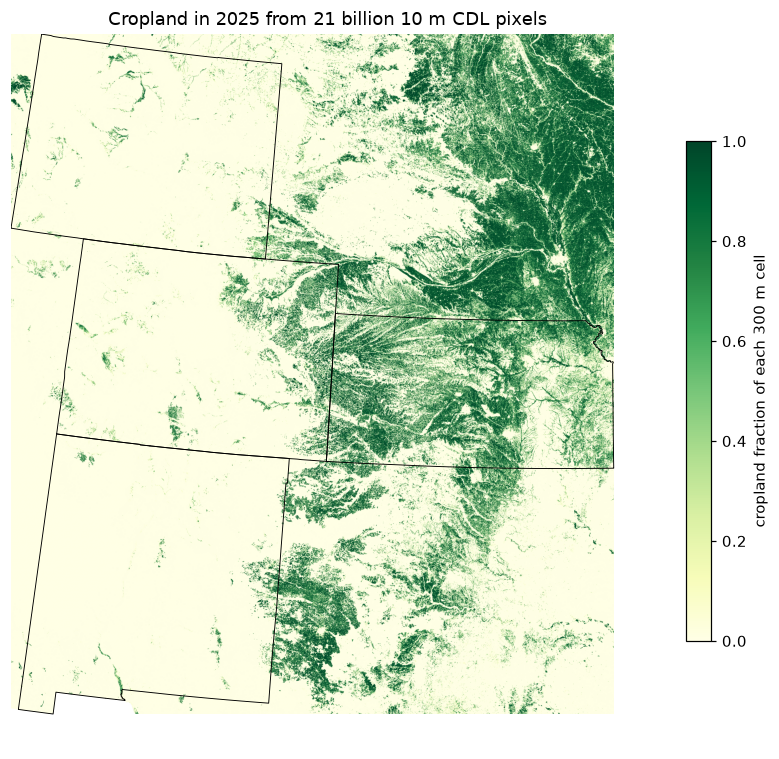

In [13]:
fig, ax = plt.subplots(figsize=(8, 7))  # one map
im = ax.imshow(frac, cmap="YlGn", vmin=0, vmax=1, extent=dd.extent(frac))  # fraction
plt.colorbar(im, ax=ax, shrink=0.7, label="cropland fraction of each 300 m cell")  # scale
dd.gp_states().boundary.plot(ax=ax, color="k", lw=0.6)  # states
ax.set_title("Cropland in 2025 from 21 billion 10 m CDL pixels"); ax.set_axis_off(); plt.tight_layout(); plt.show()  # draw

Cropland covers most of central and western Kansas, eastern Colorado and the irrigated valleys,
and almost none of the mountains and the New Mexico rangeland. The CPU and GPU runs took about the
same time: both spend nearly all of it reading and decompressing the file on the CPU. That is the
I/O-bound regime of the Overview: a GPU helps only once the data are in memory and the arithmetic
is heavy.

## Summary and exercises

- Local operations need no communication; focal operations need a halo of half the window; zonal
  and global operations need combining steps (notebooks 05 and 08).
- `calc`, `where` and `reclassify` chain into one lazy graph; a lookup table in `map_tiles` is
  the efficient way to reclassify categorical rasters.
- Chunked focal statistics, convolutions and terrain derivatives equal whole-array results,
  seams and borders included. Computed slope agreed closely with the published layer.
- GPU speed-ups followed arithmetic intensity: about an order of magnitude for memory-bound
  operations and about forty times for the 9 x 9 median.
- A moving standard deviation in float32 loses precision on large values; computing it in float64
  inside each chunk fixed that.
- All 152 billion pixels of the 10 m CDL were counted by land cover group in minutes, with peak
  memory a small fraction of the data size; a 300 m crop fraction of the Great Plains came from
  21 billion pixels. Both are limited by reading and decompression, so the GPU did not help.

**Exercises**

1. Add `pdist.raster.focal(dem, "max", size=21)` and `pdist.raster.tpi(dem, window=51)` to the
   benchmark. How do the GPU speed-ups change with window size?
2. Write the erosion classes to a COG with `pdist.write_raster(..., format="cog")` and open it in
   a GIS.
3. Count the CDL groups for Kansas only (select the Kansas bounding box first) and compare with
   the USDA's published Kansas acreages for 2025.
4. Change the crop fraction to a 1 km grid. Which chunk size must you use, and why?